In [ ]:
from aeon.benchmarking.results_loaders import get_available_estimators

get_available_estimators(task="classification")

,classification
0,1NN-DTW
1,Arsenal
2,BOSS
3,CIF
4,CNN
5,Catch22
6,DrCIF
7,EE
8,FreshPRINCE
9,GRAIL


In [4]:
classifiers = [
    "FreshPRINCEClassifier",
    "HIVECOTEV2",
    "InceptionTimeClassifier",
    "RDSTClassifier",
]
datasets = ["ACSF1", "ArrowHead", "GunPoint", "ItalyPowerDemand"]

In [5]:
from aeon.benchmarking.results_loaders import get_estimator_results

results_dict = get_estimator_results(estimators=classifiers, datasets=datasets)
results_dict["HIVECOTEV2"]["ItalyPowerDemand"]

np.float64(0.9698736637512148)

In [6]:
results_dict = get_estimator_results(
    estimators=classifiers, datasets=datasets, num_resamples=30
)
results_dict["HIVECOTEV2"]["ItalyPowerDemand"]

array([0.96987366, 0.96987366, 0.9494655 , 0.96793003, 0.96015549,
       0.96793003, 0.96793003, 0.95626822, 0.96695821, 0.96695821,
       0.96793003, 0.96695821, 0.95724004, 0.94557823, 0.96987366,
       0.96598639, 0.96501458, 0.96015549, 0.9718173 , 0.96793003,
       0.96598639, 0.95626822, 0.96112731, 0.96695821, 0.96209913,
       0.95918367, 0.96209913, 0.95918367, 0.95043732, 0.96598639])

In [7]:
import numpy as np

from aeon.visualisation import plot_series, plot_series_collection

(1, 100)


(<Figure size 1600x400 with 1 Axes>, <Axes: >)

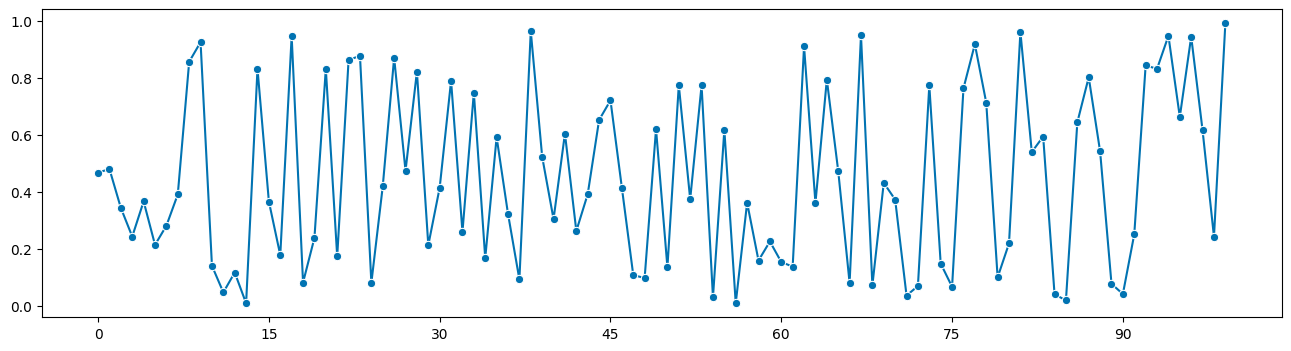

In [8]:
# Univariate series length 100
X = np.random.random((1, 100))
print(X.shape)
plot_series(X)

(3, 200)


(<Figure size 1600x400 with 1 Axes>, <Axes: >)

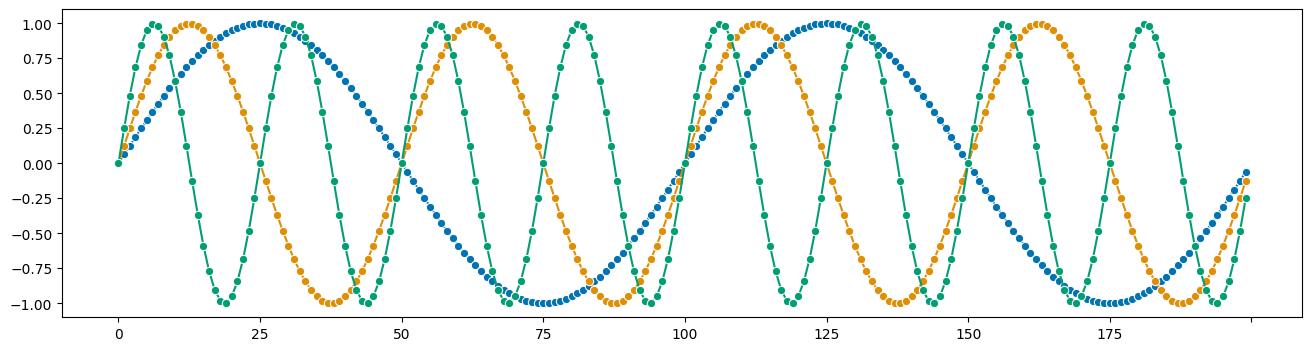

In [9]:
# Three channel multivariate series length 200
X = np.array(
    [
        np.sin(np.arange(0, np.pi * 4, np.pi * 4 / 200)),
        np.sin(np.arange(0, np.pi * 8, np.pi * 8 / 200)),
        np.sin(np.arange(0, np.pi * 16, np.pi * 16 / 200)),
    ]
)
print(X.shape)
plot_series(X)

(<Figure size 1600x400 with 1 Axes>, <Axes: >)

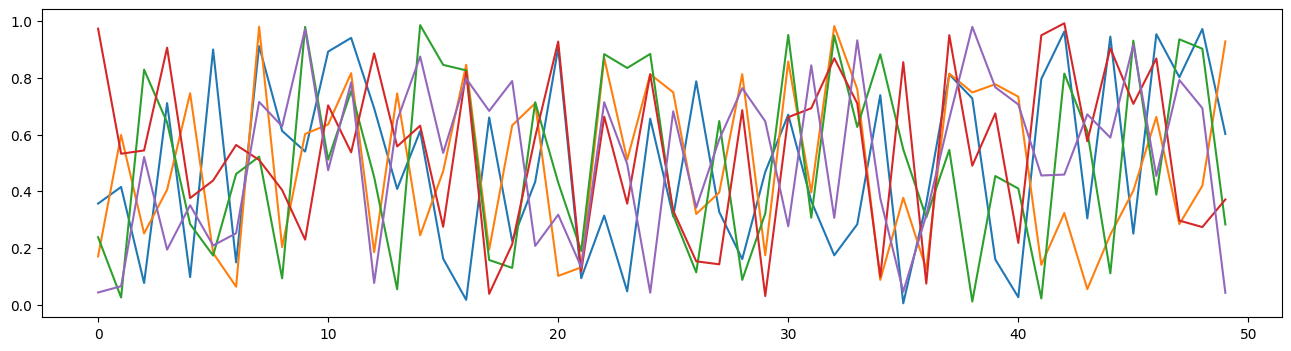

In [10]:
# Collection of 5 univariate series of length 50
X = np.random.random((5, 1, 50))
plot_series_collection(X)

(<Figure size 1600x400 with 1 Axes>, <Axes: >)

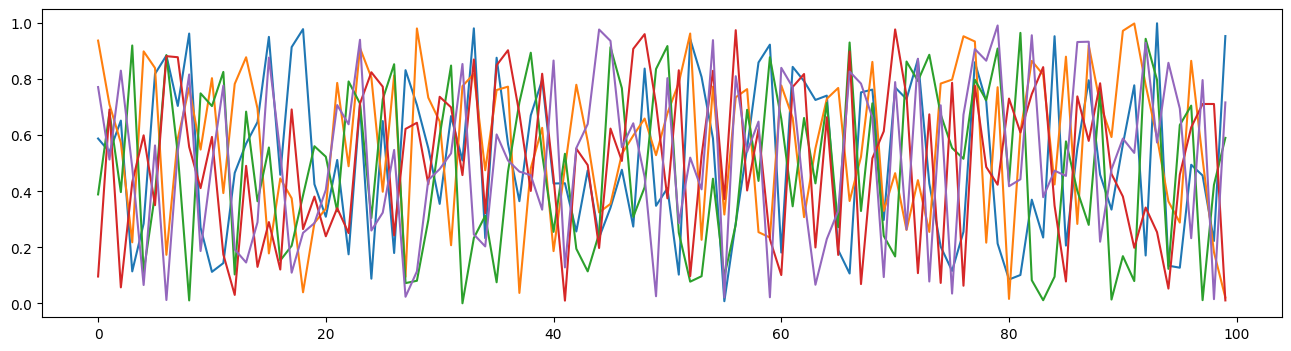

In [11]:
# Collection of 5 multivariate time series with 26 channels, length 100
X = np.random.random((5, 26, 100))
plot_series_collection(X)

In [12]:
import numpy as np

from aeon.classification import DummyClassifier
from aeon.regression import DummyRegressor

X = np.random.random((5, 1, 10))  # Collection of five series
y1 = np.array(["run", "walk", "run", "run", "walk"])
y2 = np.array([1, 0, 1, 2, 0])
y3 = np.array([0.5, 1.11, 0.545, -0.3675, 2.662])
cls = DummyClassifier()
reg = DummyRegressor()
cls.fit(X, y1)
print(cls.predict(X))
cls.fit(X, y2)
print(cls.predict(X))
reg.fit(X, y2)
print(reg.predict(X))
reg.fit(X, y3)
print(reg.predict(X))

['run' 'run' 'run' 'run' 'run']
[0 0 0 0 0]
[0.8 0.8 0.8 0.8 0.8]
[0.8899 0.8899 0.8899 0.8899 0.8899]


In [13]:
# Plotting and data loading imports used in this notebook
import matplotlib.pyplot as plt

from aeon.datasets import load_arrow_head, load_basic_motions

arrow, arrow_labels = load_arrow_head(split="train")
motions, motions_labels = load_basic_motions(split="train")
print(f"ArrowHead series of type {type(arrow)} and shape {arrow.shape}")
print(f"Motions type {type(motions)} of shape {motions_labels.shape}")

ArrowHead series of type <class 'numpy.ndarray'> and shape (36, 1, 251)
Motions type <class 'numpy.ndarray'> of shape (40,)


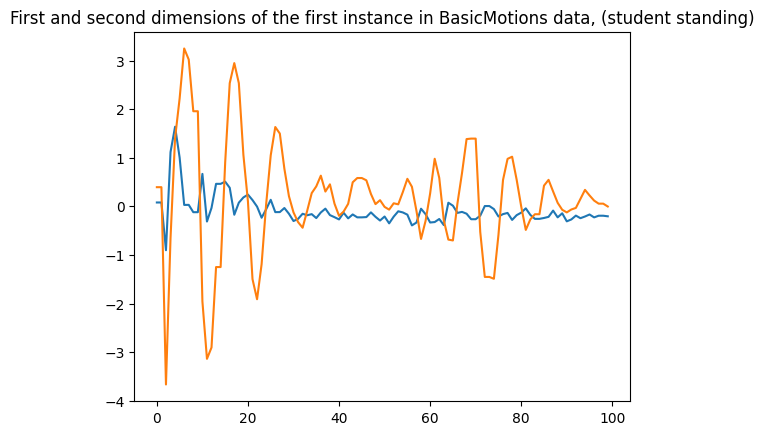

In [14]:
plt.title(
    f"First and second dimensions of the first instance in BasicMotions data, "
    f"(student {motions_labels[0]})"
)
plt.plot(motions[0][0])
plt.plot(motions[0][1])

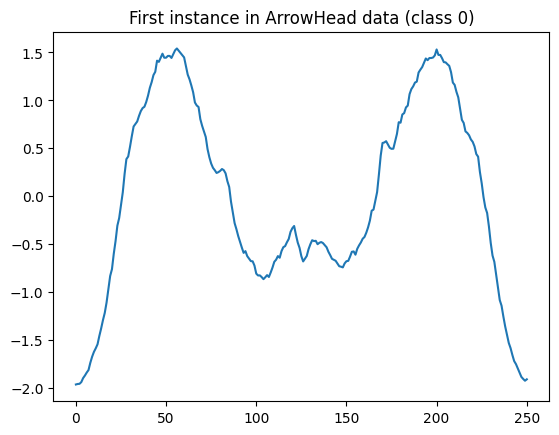

In [15]:
plt.title(f"First instance in ArrowHead data (class {arrow_labels[0]})")
plt.plot(arrow[0, 0])

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rand_forest = RandomForestClassifier(n_estimators=100)
arrow2d = arrow.squeeze()
arrow_test, arrow_test_labels = load_arrow_head(split="test", return_type="numpy2d")
rand_forest.fit(arrow2d, arrow_labels)
y_pred = rand_forest.predict(arrow_test)
accuracy_score(arrow_test_labels, y_pred)

0.7085714285714285

In [17]:
from aeon.classification.convolution_based import RocketClassifier

rocket = RocketClassifier(n_kernels=2000)
rocket.fit(arrow, arrow_labels)
y_pred = rocket.predict(arrow_test)

accuracy_score(arrow_test_labels, y_pred)

0.8171428571428572

In [18]:
from aeon.classification.hybrid import HIVECOTEV2

hc2 = HIVECOTEV2(time_limit_in_minutes=0.2)
hc2.fit(arrow, arrow_labels)
y_pred = hc2.predict(arrow_test)

accuracy_score(arrow_test_labels, y_pred)

0.8514285714285714

In [19]:
motions_test, motions_test_labels = load_basic_motions(split="test")
motions2d = motions.reshape(motions.shape[0], motions.shape[1] * motions.shape[2])
motions2d_test = motions_test.reshape(
    motions_test.shape[0], motions_test.shape[1] * motions_test.shape[2]
)
rand_forest.fit(motions2d, motions_labels)
y_pred = rand_forest.predict(motions2d_test)
accuracy_score(motions_test_labels, y_pred)

0.875

In [20]:
rocket.fit(motions, motions_labels)
y_pred = rocket.predict(motions_test)
accuracy_score(motions_test_labels, y_pred)

1.0

In [21]:
from aeon.utils.discovery import all_estimators

all_estimators(
    tag_filter={"capability:multivariate": True},
    type_filter="classifier",
)

[('Arsenal', aeon.classification.convolution_based._arsenal.Arsenal),
 ('CanonicalIntervalForestClassifier',
  aeon.classification.interval_based._cif.CanonicalIntervalForestClassifier),
 ('Catch22Classifier',
  aeon.classification.feature_based._catch22.Catch22Classifier),
 ('ClassifierChannelEnsemble',
  aeon.classification.compose._channel_ensemble.ClassifierChannelEnsemble),
 ('DisjointCNNClassifier',
  aeon.classification.deep_learning._disjoint_cnn.DisjointCNNClassifier),
 ('DrCIFClassifier',
  aeon.classification.interval_based._drcif.DrCIFClassifier),
 ('DummyClassifier', aeon.classification.dummy.DummyClassifier),
 ('ElasticEnsemble',
  aeon.classification.distance_based._elastic_ensemble.ElasticEnsemble),
 ('EncoderClassifier',
  aeon.classification.deep_learning._encoder.EncoderClassifier),
 ('FCNClassifier', aeon.classification.deep_learning._fcn.FCNClassifier),
 ('FreshPRINCEClassifier',
  aeon.classification.feature_based._fresh_prince.FreshPRINCEClassifier),
 ('HIVECOTEV